# Credit Card Fraud Detection

## 1. Project Overview

The objective of this project is to develop a machine learning model
that can identify potentially fraudulent credit card transactions. \
I will use Python, Pandas, Scikit-learn and XGBoost to explore the
transaction data, preprocess the features and train a classification model. \
Since fraud detection typically involves highly imbalanced datasets,
special attention will be paid to appropriate evaluation metrics
such as Precision, Recall, F1-Score and ROC-AUC. \
The data used for this notebook is a dataset provided on the data science community platform Kaggle and can be found under the following link:\
Link to the data: https://www.kaggle.com/datasets/neharoychoudhury/credit-card-fraud-data

**Objectives**
- Understand and explore the transaction dataset.
- Identify patterns and characteristics of fraudulent transactions.
- Prepare the data for machine learning.
- Train an XGBoost classification model.
- Evaluate the model using appropriate classification metrics.

## 2. Data Loading

In [115]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/fraud_data.csv")
df.head()

,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,trans_num,merch_lat,merch_long,is_fraud
0,04-01-2019 00:58,"""Stokes, Christiansen and Sipes""",grocery_net,14.37,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,a3806e984cec6ac0096d8184c64ad3a1,65.654142,-164.722603,1
1,04-01-2019 15:06,Predovic Inc,shopping_net,966.11,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,a59185fe1b9ccf21323f581d7477573f,65.468863,-165.473127,1
2,04-01-2019 22:37,Wisozk and Sons,misc_pos,49.61,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,86ba3a888b42cd3925881fa34177b4e0,65.347667,-165.914542,1
3,04-01-2019 23:06,Murray-Smitham,grocery_pos,295.26,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,3a068fe1d856f0ecedbed33e4b5f4496,64.445035,-166.080207,1
4,04-01-2019 23:59,Friesen Lt,health_fitness,18.17,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,891cdd1191028759dc20dc224347a0ff,65.447094,-165.446843,1


## 3. Exploratory Data Analysis

### 3.1 Dataset Overview (Data Types, Missing Values, Duplicate Rows)

In [116]:
# Number of cols and rows
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 14446
Number of columns: 15


In [117]:
# Columns
print('Columns: ' + ', '.join(df.columns))

Columns: trans_date_trans_time, merchant, category, amt, city, state, lat, long, city_pop, job, dob, trans_num, merch_lat, merch_long, is_fraud


In [118]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14446 entries, 0 to 14445
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   trans_date_trans_time  14446 non-null  str    
 1   merchant               14446 non-null  str    
 2   category               14446 non-null  str    
 3   amt                    14446 non-null  float64
 4   city                   14446 non-null  str    
 5   state                  14446 non-null  str    
 6   lat                    14446 non-null  float64
 7   long                   14446 non-null  float64
 8   city_pop               14446 non-null  int64  
 9   job                    14446 non-null  str    
 10  dob                    14446 non-null  str    
 11  trans_num              14446 non-null  str    
 12  merch_lat              14446 non-null  float64
 13  merch_long             14446 non-null  float64
 14  is_fraud               14446 non-null  str    
dtypes: float64(5)

**Observation:** Data does not contain missing values

In [119]:
# Statistical description of numerical features
df.describe()

,amt,lat,long,city_pop,merch_lat,merch_long
count,14446.000000,14446.000000,14446.000000,1.444600e+04,14446.000000,14446.000000
mean,124.430073,39.787692,-110.874225,1.065370e+05,39.787991,-110.874892
std,231.352587,5.317039,12.985813,2.902916e+05,5.360593,12.995596
min,1.000000,20.027100,-165.672300,4.600000e+01,19.032689,-166.670685
25%,12.080000,36.715400,-120.415800,4.930000e+02,36.794655,-120.146253
50%,51.520000,39.666200,-111.098500,1.645000e+03,39.620953,-111.192629
75%,101.030000,41.940400,-101.136000,3.543900e+04,42.275740,-100.446822
max,3261.470000,66.693300,-89.628700,2.383912e+06,67.510267,-88.646366


In [120]:
# Statistical description of categorical data
df.describe(include=['str'])

,trans_date_trans_time,merchant,category,city,state,job,dob,trans_num,is_fraud
count,14446,14446,14446,14446,14446,14446,14446,14446,14446
unique,12126,693,14,176,13,163,187,14383,4
top,26-12-2020 23:29,Kilback LLC,grocery_pos,Phoenix,CA,"""Surveyor, minerals""",17-07-1989,a3806e984cec6ac0096d8184c64ad3a1,0
freq,5,58,1602,297,3375,262,197,2,12600


In [121]:
# Check for duplicates
print(f"Number of duplicate rows: {df.duplicated().sum()}")

duplicate_percentage = df.duplicated().mean() * 100

print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Number of duplicate rows: 63
Duplicate percentage: 0.44%


### 3.2 Target Variable Analysis

In [122]:
TARGET = 'is_fraud'

# Absolute distribution
df[TARGET].value_counts()

is_fraud
0                         12600
1                          1844
1"2020-12-24 16:56:24"        1
0"2019-01-01 00:00:44"        1
Name: count, dtype: int64

In [123]:
# Percentage
df[TARGET].value_counts(normalize=True) * 100

is_fraud
0                         87.221376
1                         12.764779
1"2020-12-24 16:56:24"     0.006922
0"2019-01-01 00:00:44"     0.006922
Name: proportion, dtype: float64

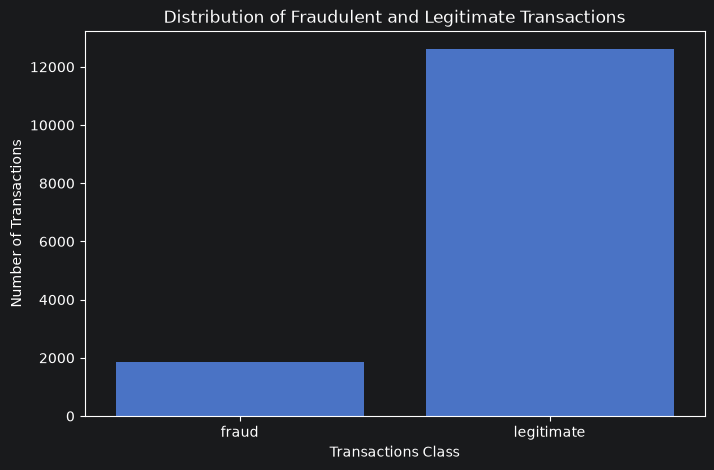

In [124]:
# Visualization (exclude the two corrupted rows)
df = df.loc[~(df.is_fraud.isin(['1"2020-12-24 16:56:24"', '0"2019-01-01 00:00:44"']))]

plt.figure(figsize = (8,5))

sns.countplot(data=df, x=TARGET)

plt.title('Distribution of Fraudulent and Legitimate Transactions')
plt.xticks(ticks = [0,1], labels = ['fraud', 'legitimate'])
plt.xlabel("Transactions Class")
plt.ylabel("Number of Transactions")

plt.show()

**Conclusion:**\
As expected the dataset is unbalanced with much more legitimate transactions then fraudulent transactions (~ 87% to 13%).\
There are two rows that seem ok but have a corrupted entry in the target column. Decision is to drop the two rows.

### 3.3 Numerical Feature Analysis

In [125]:
numerical_features = df.select_dtypes(include=np.number).columns.tolist()
numerical_features

['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long']

#### 3.3.1 Amount (amt) Analysis

In [126]:
# Descriptive Statistics
df.amt.describe()

count    14444.000000
mean       124.445403
std        231.364927
min          1.000000
25%         12.080000
50%         51.540000
75%        101.032500
max       3261.470000
Name: amt, dtype: float64

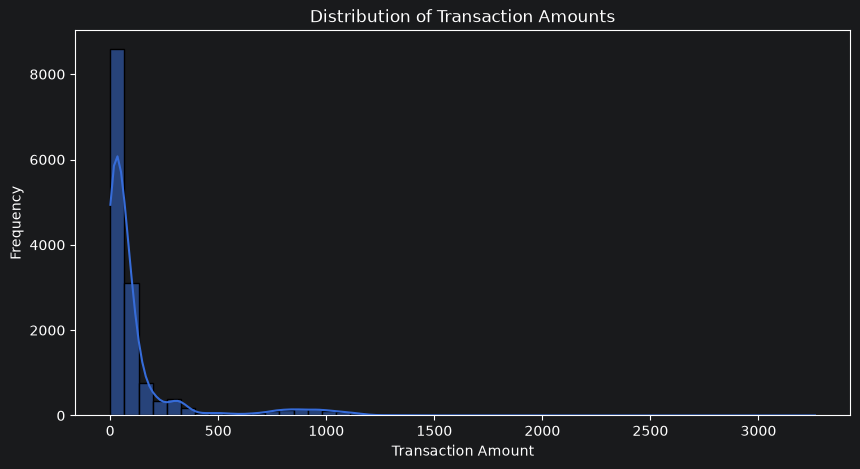

In [127]:
# Distribution Analysis
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='amt', bins=50, kde=True)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

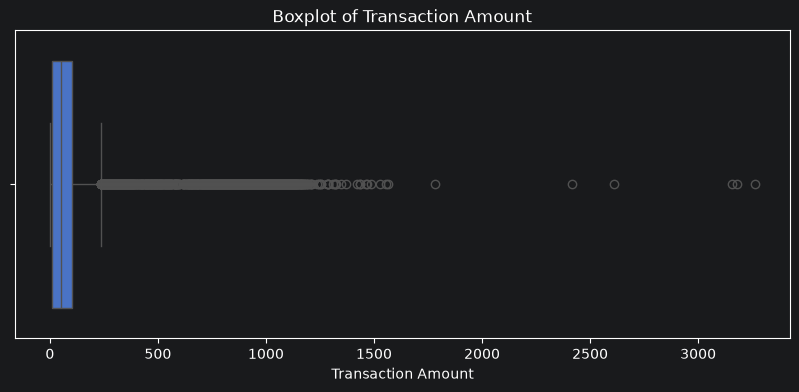

In [128]:
# Outlier Analysis
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df['amt']
)

plt.title("Boxplot of Transaction Amount")
plt.xlabel("Transaction Amount")

plt.show()

In [129]:
# Fraud vs. Non-Fraud Comparison
df.groupby('is_fraud')['amt'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,12600.0,66.814898,114.481015,1.00,9.77,46.140,81.9275,3261.47
1,1844.0,518.233015,389.925972,1.78,187.35,358.655,884.2225,1371.81


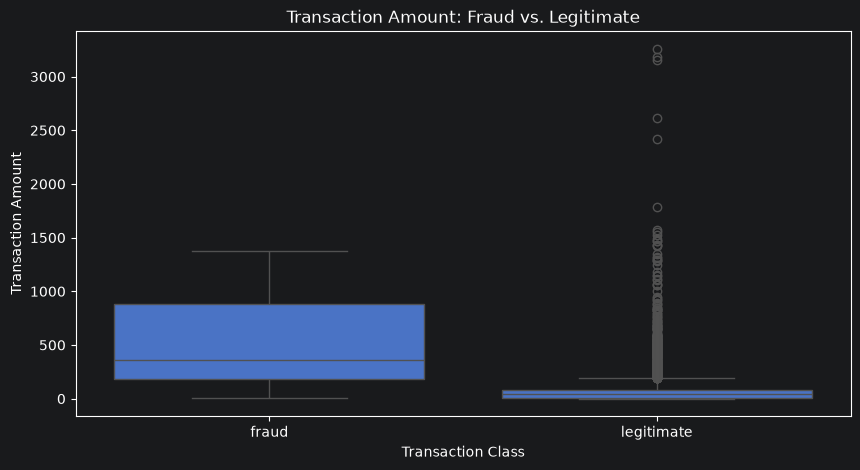

In [130]:
# Visualize
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="is_fraud", y="amt")

plt.xticks(ticks=[0,1], labels=['fraud', 'legitimate'])
plt.title("Transaction Amount: Fraud vs. Legitimate")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")

plt.show()

**Conclusion:**\
The Amount feature shows a noticeable difference between fraudulent and legitimate transactions.\
Fraudulent transactions tend to involve significantly higher amounts, making this feature potentially valuable for the classification model.

### 3.4 Categorical Feature Analysis

### 3.5 Other Features Analysis

### 3.6 Conclusion

**TARGET (is_fraud):**\
fraudulent: 12600 (~87%)\
legit: 1844 (~13%)\
Deleted two rows with corrupted entries.

#### Numerical Features
**Amount (amt):**\
The Amount feature shows a noticeable difference between fraudulent and legitimate transactions.\
Fraudulent transactions tend to involve significantly higher amounts, making this feature potentially valuable for the classification model.
